In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("netflix_titles.csv")

print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [4]:
print("First 5 rows:")
print(df.head())

print("Dataset Shape:")
print(df.shape)

print("Dataset Information:")
df.info()

print("Statistical Description:")
print(df.describe(include="all"))

print("Column Names:")
print(df.columns)

First 5 rows:
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24

In [5]:

df.drop("show_id", axis=1, inplace=True)
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["type"] = df["type"].astype("string")

print(df.head())

      type                  title         director  \
0    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1  TV Show          Blood & Water              NaN   
2  TV Show              Ganglands  Julien Leclercq   
3  TV Show  Jailbirds New Orleans              NaN   
4  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

  date_added  release_year rating   duration  \
0 2021-09-25          2020  PG-13     90 min   
1 2021-09-24          2021  TV-MA  2 Seasons   
2 2021-09-24          2021  TV-MA   1 Season   
3 2021-09-24          2021  TV-MA   1 Season   
4 2021-0

In [6]:
print(df.isnull().sum())

type               0
title              0
director        2634
cast             825
country          831
date_added        98
release_year       0
rating             4
duration           3
listed_in          0
description        0
year_added        98
dtype: int64


In [7]:

df["release_year"] = df["release_year"].fillna(
    df["release_year"].mean()
)


duration_num = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

mean_duration = duration_num.mean()

df["duration"] = df["duration"].fillna(
    str(round(mean_duration)) + " min"
)


df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna("Unknown")
df["date_added"] = df["date_added"].fillna(pd.Timestamp("2000-01-01"))

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
type             0
title            0
director         0
cast             0
country          0
date_added       0
release_year     0
rating           0
duration         0
listed_in        0
description      0
year_added      98
dtype: int64


In [9]:

print(df["type"].value_counts())
print(df["country"].value_counts().head(10))
print(df["year_added"].value_counts().sort_index())
print(df["listed_in"].value_counts().head(10))
print(df[df["release_year"] > 2015].shape[0])
print(df[df["type"] == "Movie"].shape[0])
print(df[df["type"] == "TV Show"].shape[0])

type
Movie      6131
TV Show    2676
Name: count, dtype: Int64
country
United States     2818
India              972
Unknown            831
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      10
2014.0      23
2015.0      73
2016.0     418
2017.0    1164
2018.0    1625
2019.0    1999
2020.0    1878
2021.0    1498
Name: count, dtype: int64
listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            220
Children & Family Movies                            215
Children & Family Movies

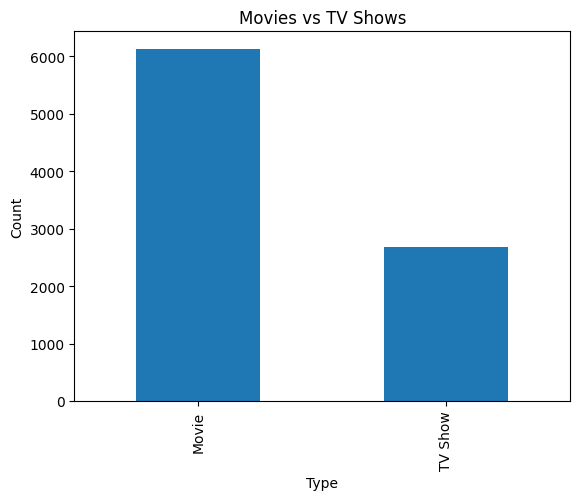

In [10]:
df["type"].value_counts().plot(
    kind="bar",
    title="Movies vs TV Shows"
)

plt.xlabel("Type")
plt.ylabel("Count")
plt.show()

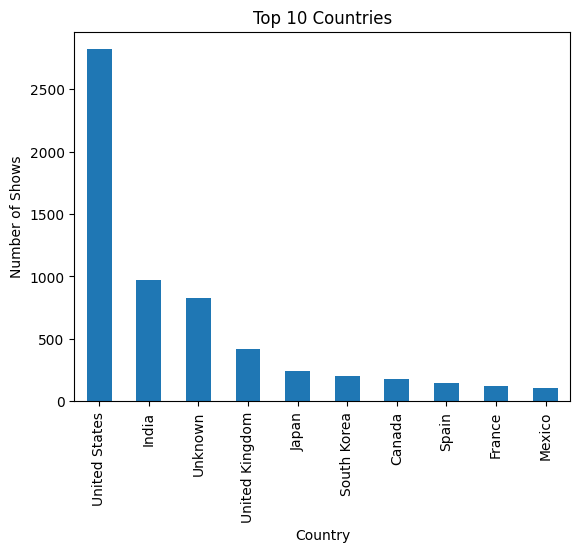

In [11]:
df["country"].value_counts().head(10).plot(
    kind="bar",
    title="Top 10 Countries"
)

plt.xlabel("Country")
plt.ylabel("Number of Shows")
plt.show()

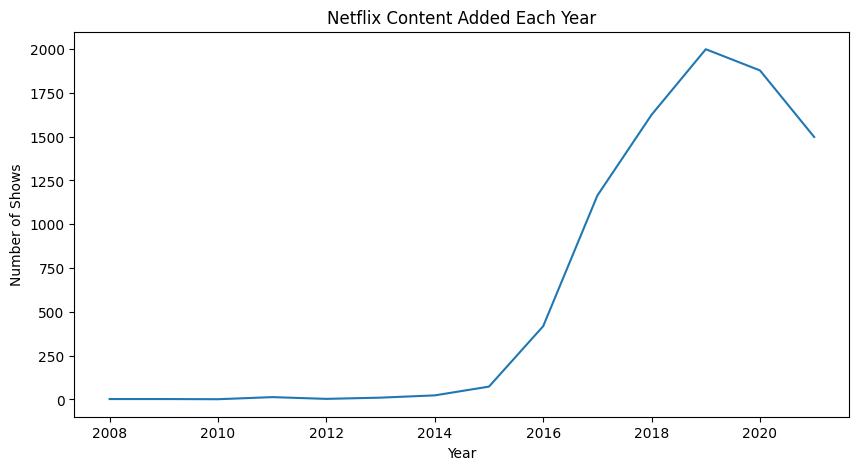

In [12]:
df["year_added"].value_counts().sort_index().plot(
    kind="line",
    figsize=(10,5),
    title="Netflix Content Added Each Year"
)

plt.xlabel("Year")
plt.ylabel("Number of Shows")
plt.show()

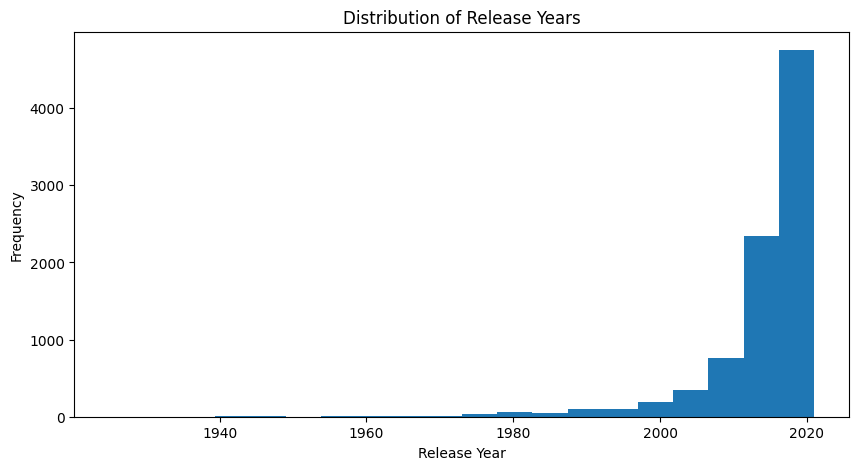

In [13]:
plt.figure(figsize=(10,5))

plt.hist(df["release_year"], bins=20)

plt.title("Distribution of Release Years")
plt.xlabel("Release Year")
plt.ylabel("Frequency")

plt.show()